# Handwriting Recognition Neural Network From Scratch
This notebook demonstrates how to load the MNIST dataset and build a simple Feedforward Neural Network from scratch using only NumPy.

# Read This First — What You Are Building

You built a handwritten-digit classifier for the MNIST dataset. Given a 28 × 28 grayscale image, the neural network predicts one of ten classes: digits 0 through 9.

This is a **supervised, multi-class classification** problem. The training examples contain both an image and its correct label. The network starts with randomly initialized weights and biases, produces predictions, computes gradients using the chain rule, and adjusts its parameters with gradient descent.

### What “from scratch” means here

The model's dense layers, ReLU, softmax, forward propagation, backpropagation, accuracy calculation, and gradient-descent update are your own NumPy code. TensorFlow/Keras is used only as a convenient MNIST data loader; it does not build or train this network.

### How to use this notebook

Run the cells from top to bottom. For each mathematical operation, check the tensor shape before trying to memorize the formula. The core habit for understanding backpropagation is to trace both:

1. **The values flowing forward** to make a prediction.
2. **The gradients flowing backward** to quantify how each parameter affects the loss.

The original code and training output are preserved below, with additional explanations and a separate full-test evaluation at the end.

# 1. Dataset: what do these dimensions mean?

MNIST contains 60,000 training images and 10,000 test images. Each image is a 28-row by 28-column array of grayscale pixel values. A label is an integer from 0 to 9.

The raw image tensor has shape **(number of images, height, width)**. Therefore, (60000, 28, 28) means sixty thousand separate images—not one image with sixty thousand channels.

The training set is the data used to learn the parameters. The test set must remain outside the gradient updates so it can provide an estimate of generalization to unseen examples. The notebook later plots three test images; that is a useful sanity check, but three examples do not measure full test accuracy.

TensorFlow/Keras is only used to load this public dataset. The network itself is built with NumPy.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

# Load the public MNIST dataset of handwritten digits
(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = mnist.load_data()

# Let's inspect the shapes of our pixel matrices
print(f"Training images shape: {X_train_raw.shape}")
print(f"Test images shape: {X_test_raw.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images shape: (60000, 28, 28)
Test images shape: (10000, 28, 28)


# Data is loaded — quick observation

The shapes printed above correspond to 60,000 training examples and 10,000 test examples. We next convert the images to the matrix orientation used by the neural-network formulas.

### Preprocessing
We flatten each 28x28 pixel matrix into a 784-element vector, and normalize the pixel values from [0, 255] to [0, 1].

In [2]:
# Flatten and normalize pixel inputs
X_train = X_train_raw.reshape(X_train_raw.shape[0], -1).T / 255.0
X_test = X_test_raw.reshape(X_test_raw.shape[0], -1).T / 255.0

# Helper function to convert labels to one-hot encoding
def one_hot(Y):
    one_hot_Y = np.zeros((Y.size, 10))
    one_hot_Y[np.arange(Y.size), Y] = 1
    return one_hot_Y.T

Y_train = one_hot(y_train_raw)
Y_test = one_hot(y_test_raw)

print(f"Flattened Input shape: {X_train.shape}")
print(f"One-hot target shape: {Y_train.shape}")

Flattened Input shape: (784, 60000)
One-hot target shape: (10, 60000)


# 2. Preprocessing and one-hot labels

## Flattening each image

Each image has 28 × 28 = 784 pixel positions. The reshape converts each 28 × 28 grid into a vector with 784 elements. The transpose then places **features in rows and examples in columns**:

- Before flattening: (60000, 28, 28)
- After reshape: (60000, 784)
- After transpose: (784, 60000)

This orientation is a design choice, not a universal NumPy rule. It allows one matrix multiplication to process an entire batch: W1 has shape (64, 784) and X has shape (784, m), so W1 @ X has shape (64, m).

## Normalization

Pixel intensities originally range from 0 to 255. Dividing by 255 scales them to 0 through 1. This is simple range scaling, not z-score standardization. Keeping input values modest tends to make optimization more manageable.

## One-hot encoding

The network has ten output units, one for each digit. A label such as 3 is represented as a length-10 vector with a 1 at class 3 and zeros elsewhere:

~~~text
[0, 0, 0, 1, 0, 0, 0, 0, 0, 0]
~~~

The code first creates a zero matrix, writes a 1 at the true class for each row, then transposes. The final Y shape is (10, number of examples), matching the output matrix A2.

**Remember:** X contains model inputs; Y contains target labels encoded as one-hot columns.

### Neural Network Implementation
We will build a simple network with one hidden layer:
- Input: 784 nodes (pixels)
- Hidden layer: 64 nodes (ReLU activation)
- Output layer: 10 nodes (Softmax activation for classes 0-9)

In [3]:
def init_params():
    # He/Xavier-like initialization
    W1 = np.random.randn(64, 784) * np.sqrt(2.0 / 784)
    b1 = np.zeros((64, 1))
    W2 = np.random.randn(10, 64) * np.sqrt(2.0 / 64)
    b2 = np.zeros((10, 1))
    return W1, b1, W2, b2

def ReLU(Z):
    return np.maximum(0, Z)

def ReLU_deriv(Z):
    return Z > 0

def softmax(Z):
    exp_Z = np.exp(Z - np.max(Z, axis=0, keepdims=True))
    return exp_Z / np.sum(exp_Z, axis=0, keepdims=True)

def forward_prop(W1, b1, W2, b2, X):
    Z1 = np.dot(W1, X) + b1
    A1 = ReLU(Z1)
    Z2 = np.dot(W2, A1) + b2
    A2 = softmax(Z2)
    return Z1, A1, Z2, A2

def backward_prop(Z1, A1, Z2, A2, W1, W2, X, Y):
    m = Y.shape[1]
    dZ2 = A2 - Y
    dW2 = (1 / m) * np.dot(dZ2, A1.T)
    db2 = (1 / m) * np.sum(dZ2, axis=1, keepdims=True)

    dZ1 = np.dot(W2.T, dZ2) * ReLU_deriv(Z1)
    dW1 = (1 / m) * np.dot(dZ1, X.T)
    db1 = (1 / m) * np.sum(dZ1, axis=1, keepdims=True)
    return dW1, db1, dW2, db2

def update_params(W1, b1, W2, b2, dW1, db1, dW2, db2, alpha):
    W1 = W1 - alpha * dW1
    b1 = b1 - alpha * db1
    W2 = W2 - alpha * dW2
    b2 = b2 - alpha * db2
    return W1, b1, W2, b2

def get_predictions(A2):
    return np.argmax(A2, axis=0)

def get_accuracy(predictions, Y):
    return np.sum(predictions == np.argmax(Y, axis=0)) / Y.shape[1]

# 3. Understand every moving part of the network

The architecture is **784 → 64 → 10**:

- 784 input features: normalized pixels.
- 64 hidden neurons: learn intermediate combinations of pixel patterns.
- 10 output neurons: assign scores to digits 0 through 9.

There are two trainable weight matrices and two bias vectors:

| Parameter | Shape | Role |
|---|---|---|
| W1 | (64, 784) | Connect 784 inputs to 64 hidden neurons |
| b1 | (64, 1) | One bias per hidden neuron |
| W2 | (10, 64) | Connect 64 hidden neurons to 10 output units |
| b2 | (10, 1) | One bias per output class |

The parameter count is 64 × 784 + 64 + 10 × 64 + 10 = **50,890**.

## Initialization

Weights are randomly initialized so neurons do not all begin symmetrically with identical behavior. The scale sqrt(2 / fan_in) is commonly associated with He initialization for ReLU networks. Biases start at zero. The original comment says “He/Xavier-like”; technically, the formula used here is He-style scaling.

## ReLU

ReLU(z) = max(0, z). Negative pre-activations become zero, while positive values pass through. This nonlinearity is important: stacking only linear layers without nonlinear activations would still give a linear transformation overall.

## Softmax

The output layer computes ten logits, then softmax converts the logits into non-negative values that sum to one for each image. Softmax is applied **down the class rows for each column/image**, hence axis=0 in this notebook.

The implementation subtracts the maximum logit before exponentiation. Adding or subtracting the same constant from every logit does not change softmax probabilities, but subtracting the maximum improves numerical stability by reducing the risk of overflow.

## Forward propagation

~~~text
Z1 = W1 @ X + b1
A1 = ReLU(Z1)
Z2 = W2 @ A1 + b2
A2 = softmax(Z2)
~~~

Z1 and Z2 are pre-activations/logits; A1 and A2 are activations after applying the nonlinear functions. Forward propagation calculates values only—it does not update the weights.

Here is the derivative rather than just the result. For one example, softmax is:

~~~text
p_k = exp(z_k) / sum_l exp(z_l)
~~~

Its derivative is:

~~~text
dp_k/dz_j = p_k * (1[k = j] - p_j)
~~~

The expression 1[k = j] is 1 when the indices match and 0 otherwise. Cross-entropy is L = -sum_k y_k * log(p_k). Apply the chain rule:

~~~text
dL/dz_j = -sum_k y_k * (1/p_k) * (dp_k/dz_j)
         = -sum_k y_k * (1[k = j] - p_j)
         = -y_j + p_j * sum_k y_k
         = p_j - y_j
~~~

The last step uses sum_k y_k = 1, which is true for a one-hot target. Thus the combined softmax/cross-entropy derivative is p - y. Your code delays the factor 1/m for the batch mean until dW and db are calculated.

# Cross-entropy helper

The original gradient formula corresponds to categorical cross-entropy, even though the training loop does not print that loss. This helper makes the objective explicit and will be used in the final evaluation cell.

In [ ]:
def cross_entropy_loss(A2, Y):
    """Mean categorical cross-entropy for one-hot targets.

    This makes the objective implied by the original A2 - Y gradient explicit.
    """
    m = Y.shape[1]
    probabilities = np.clip(A2, 1e-12, 1.0)
    return -np.sum(Y * np.log(probabilities)) / m


### Training Loop
Let's run gradient descent for 150 epochs to train the network.

# 5. Training: full-batch gradient descent

The original loop runs 150 epochs with alpha = 0.15. An epoch is one pass through the full training set. Because the entire matrix of 60,000 examples is passed into forward propagation and backpropagation at once, this is **full-batch gradient descent**, not mini-batch training.

Each epoch performs these steps:

1. Compute the predictions using the current weights.
2. Calculate gradients for all four parameter arrays.
3. Subtract learning-rate times each gradient.
4. Occasionally print an accuracy metric.

Full-batch training is pedagogically clear because each update uses all training examples. It can also require substantial memory and compute. A mini-batch version divides the examples into smaller groups and performs more frequent updates.

### Accuracy timing detail

In your original loop, A2 is calculated **before** the parameter update. Then the weights update, but the printed accuracy is calculated from that old A2. Thus the printed metric describes the pre-update forward pass in that iteration. The number is still a useful progress signal, but a polished implementation usually evaluates after the update or labels it explicitly.

The notebook's reported 89.88% at epoch 150 is training accuracy. It is not full test accuracy. Accuracy checks only which class has the largest probability; cross-entropy is more sensitive to how much probability the model assigns to the correct class.

In [7]:
def gradient_descent(X, Y, epochs, alpha):
    W1, b1, W2, b2 = init_params()
    for i in range(1, epochs + 1):
        Z1, A1, Z2, A2 = forward_prop(W1, b1, W2, b2, X)
        dW1, db1, dW2, db2 = backward_prop(Z1, A1, Z2, A2, W1, W2, X, Y)
        W1, b1, W2, b2 = update_params(W1, b1, W2, b2, dW1, db1, dW2, db2, alpha)

        if i % 15 == 0 or i == 1:
            predictions = get_predictions(A2)
            acc = get_accuracy(predictions, Y)
            print(f"Epoch {i:3d} - Accuracy: {acc*100:.2f}%")
    return W1, b1, W2, b2

W1, b1, W2, b2 = gradient_descent(X_train, Y_train, epochs=150, alpha=0.15)

Epoch   1 - Accuracy: 7.10%
Epoch  15 - Accuracy: 71.71%
Epoch  30 - Accuracy: 81.55%
Epoch  45 - Accuracy: 84.72%
Epoch  60 - Accuracy: 86.46%
Epoch  75 - Accuracy: 87.55%
Epoch  90 - Accuracy: 88.27%
Epoch 105 - Accuracy: 88.83%
Epoch 120 - Accuracy: 89.23%
Epoch 135 - Accuracy: 89.59%
Epoch 150 - Accuracy: 89.88%


# The observed learning curve

In the stored output, training accuracy rises gradually from 7.10% at epoch 1 to 89.88% at epoch 150. The later evaluation cell will compute full-set training and test metrics separately.

### Test Model Predictions
We can test our trained parameters on a few images from the test set.

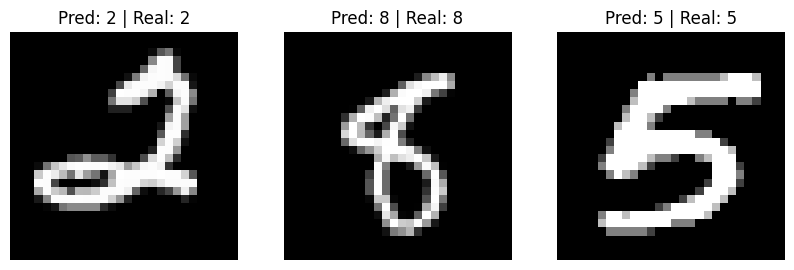

In [7]:
def make_predictions(X, W1, b1, W2, b2):
    _, _, _, A2 = forward_prop(W1, b1, W2, b2, X)
    return get_predictions(A2)

# Predict and plot 3 random samples from test dataset
fig, axes = plt.subplots(1, 3, figsize=(10, 4))
for idx, ax in enumerate(axes):
    sample_idx = np.random.randint(0, X_test.shape[1])
    # Use list indexing [sample_idx] to keep the 2D column shape (784, 1) safely
    current_image = X_test[:, [sample_idx]]
    prediction = make_predictions(current_image, W1, b1, W2, b2)[0]
    label = y_test_raw[sample_idx]

    ax.imshow(X_test_raw[sample_idx], cmap='gray')
    ax.set_title(f"Pred: {prediction} | Real: {label}")
    ax.axis('off')
plt.show()

# 6. Reading the results and evaluating properly

The updated raw notebook output shows training accuracy rising from 7.10% at epoch 1 to 89.88% at epoch 150. This is evidence that the weights are learning useful patterns. The initial result is near the 10% scale associated with chance-level guessing over ten classes, but that alone does not prove correctness or generalization.

The final added code cell below computes:
- mean cross-entropy on the training set;
- accuracy over the entire training set;
- mean cross-entropy on the entire held-out test set;
- accuracy over all 10,000 test images.

It performs inference only on the test set; no test examples are used for gradient updates. Use a validation set when tuning hyperparameters in repeated experiments, then report the held-out test result as a final evaluation.

### Limits of this first project

- The images are flattened, so the model is not explicitly built to exploit local image neighborhoods.
- The original loop uses full-batch gradients.
- The original training output does not log the loss.
- Only three test images are plotted in the original visualization.
- The original loop doesn't set a seed, so runs may vary.
- It does not reserve a separate validation set for selecting epochs or the learning rate.

These are reasonable limitations for a first from-scratch educational model. They also give you clear next experiments.

In [ ]:
# Evaluate the trained model on all training and test examples.
# This is a forward pass only; these calls do not update parameters.
_, _, _, train_probabilities = forward_prop(W1, b1, W2, b2, X_train)
_, _, _, test_probabilities = forward_prop(W1, b1, W2, b2, X_test)

train_loss = cross_entropy_loss(train_probabilities, Y_train)
test_loss = cross_entropy_loss(test_probabilities, Y_test)
train_accuracy = get_accuracy(get_predictions(train_probabilities), Y_train)
test_accuracy = get_accuracy(get_predictions(test_probabilities), Y_test)

print(f"Training cross-entropy: {train_loss:.4f}")
print(f"Training accuracy:     {train_accuracy * 100:.2f}%")
print(f"Test cross-entropy:     {test_loss:.4f}")
print(f"Test accuracy:          {test_accuracy * 100:.2f}%")


# 7. Practice until backpropagation is clear

Try answering without looking back at the derivation:

1. Why does dZ2 equal A2 - Y for a softmax output with categorical cross-entropy?
2. Why does dW2 use A1.T while dW1 uses X.T?
3. What does W2.T @ dZ2 represent in ordinary language?
4. Why is the ReLU derivative multiplied elementwise?
5. Why must dW1 have the same shape as W1?
6. Why are parameter gradients divided by the number of examples?
7. What is the difference between a gradient and a parameter update?
8. Why doesn't the original 89.88% training metric establish 89.88% test accuracy?
9. What might happen if the learning rate is too large?
10. How would you verify a backpropagated gradient independently?

### Suggested next experiment

Create a tiny network with only a few weights and one or two examples. For one parameter w, estimate the derivative numerically:

~~~text
numerical_gradient ≈ (L(w + epsilon) - L(w - epsilon)) / (2 * epsilon)
~~~

Compare it with the analytical gradient from backpropagation. Use a small epsilon, test several parameters, and avoid a ReLU kink where finite differences can be misleading. Agreement within a reasonable numerical tolerance is a powerful check that your chain-rule implementation is correct.

# 8. Optimization: calculus, loss functions, and the optimizer

## Why not simply set dy/dx = 0?

For a differentiable one-variable function f(x), an interior local minimum has f'(x) = 0. This is a necessary condition under the stated assumptions, not a complete method for finding the global minimum. A stationary point can be a local minimum, a local maximum, or a saddle/flat point. Boundary minima are another possibility. For example, f(x) = x^3 has derivative zero at x = 0, but that point is not a minimum. For f(x) = x^2, setting f'(x) = 2x to zero gives x = 0, which is the global minimum because this particular function is convex and simple.

A neural network does not have one scalar x. Its loss depends on all parameters together:

~~~text
J(theta) = J(W1, b1, W2, b2)
~~~

This network has 50,890 trainable scalar parameters. A stationary point would require all partial derivatives to vanish simultaneously:

~~~text
gradient_theta J(theta) = 0
~~~

That is a system of 50,890 coupled equations. The parameters interact through matrix multiplications and nonlinear activations. ReLU makes the objective piecewise-defined, and neural-network objectives are generally non-convex. There can be many stationary points, local minima, saddle points, and flat regions. There is no practical closed-form solution that solves this system and certifies a global minimum for this network.

Calculus is not being ignored. **Backpropagation is calculus**: it applies the chain rule to calculate the partial derivative of the loss with respect to every weight and bias. The optimizer then uses those gradients to choose parameter updates. The practical goal is to find parameters with low loss and good performance on unseen data—not to prove that the global minimum has been reached.

## Which loss function is used?

This notebook does not explicitly compute or print a loss in either training loop. However, its output-layer formula dZ2 = A2 - Y is the standard derivative for **softmax combined with categorical cross-entropy**, when targets are one-hot encoded and the objective is averaged over examples.

For one example:

~~~text
L = -sum_k y_k * log(p_k)
~~~

Because y is one-hot, the expression becomes L = -log(p_correct). The network receives a large penalty when it assigns very low probability to the correct digit.

MAE and RMSE are common for regression, where predictions are numeric quantities such as prices. They can technically be calculated between one-hot vectors and predicted probabilities, so they are not forbidden in classification. However, cross-entropy is the usual probability-aware objective for this ten-class softmax classifier. It directly penalizes low probability assigned to the correct class. Accuracy is an evaluation metric rather than the differentiable loss being optimized.

## Why is the printed 96.14% not enough?

The saved output measures **training accuracy**, not test accuracy. It does not show the accuracy on all 10,000 held-out test images. It also uses a different learning rate and a fresh random initialization for each optimizer. The displayed accuracy is computed from A2 before the parameter update in that epoch.

The two printed results are useful observations from these particular runs. To make a strong comparison, use the same initial weights, tune each optimizer on validation data, calculate metrics after updates, and evaluate the selected models on the untouched test set.

## Adam: how the optimizer changes the update

Vanilla gradient descent uses the gradient directly:

~~~text
theta = theta - alpha * gradient
~~~

Adam still receives the same gradients from backpropagation, but keeps two moving averages for every parameter:

- First moment m: an exponentially weighted average of recent gradients. It smooths the update direction, similar to momentum.
- Second raw moment v: an exponentially weighted average of squared gradients. It tracks the recent scale of each parameter's gradients.

For a gradient g at step t:

~~~text
m_t = beta1 * m_(t-1) + (1 - beta1) * g_t
v_t = beta2 * v_(t-1) + (1 - beta2) * (g_t ** 2)
~~~

Because both averages start at zero, Adam corrects their early bias:

~~~text
m_hat_t = m_t / (1 - beta1 ** t)
v_hat_t = v_t / (1 - beta2 ** t)
~~~

Then each parameter is updated elementwise:

~~~text
theta_t = theta_(t-1) - alpha * m_hat_t / (sqrt(v_hat_t) + epsilon)
~~~

In this notebook beta1 = 0.9, beta2 = 0.999, epsilon = 1e-8, and alpha = 0.003. Adam combines momentum-like smoothing with adaptive per-parameter update scales. It does not replace backpropagation; it changes how the resulting gradients are used.

**Important: this is Adam, not AdamW.** AdamW includes decoupled weight decay. The function below has no weight-decay argument or decay operation.

In [ ]:
def adam_optimizer(X, Y, epochs, alpha, beta1=0.9, beta2=0.999, epsilon=1e-8):
    W1, b1, W2, b2 = init_params()

    # First-moment and second-moment state for every parameter.
    m_W1, v_W1 = np.zeros_like(W1), np.zeros_like(W1)
    m_b1, v_b1 = np.zeros_like(b1), np.zeros_like(b1)
    m_W2, v_W2 = np.zeros_like(W2), np.zeros_like(W2)
    m_b2, v_b2 = np.zeros_like(b2), np.zeros_like(b2)

    for t in range(1, epochs + 1):
        Z1, A1, Z2, A2 = forward_prop(W1, b1, W2, b2, X)
        dW1, db1, dW2, db2 = backward_prop(
            Z1, A1, Z2, A2, W1, W2, X, Y
        )

        # Exponential moving averages of gradients and squared gradients.
        m_W1 = beta1 * m_W1 + (1 - beta1) * dW1
        m_b1 = beta1 * m_b1 + (1 - beta1) * db1
        m_W2 = beta1 * m_W2 + (1 - beta1) * dW2
        m_b2 = beta1 * m_b2 + (1 - beta1) * db2

        v_W1 = beta2 * v_W1 + (1 - beta2) * (dW1 ** 2)
        v_b1 = beta2 * v_b1 + (1 - beta2) * (db1 ** 2)
        v_W2 = beta2 * v_W2 + (1 - beta2) * (dW2 ** 2)
        v_b2 = beta2 * v_b2 + (1 - beta2) * (db2 ** 2)

        # Bias correction for the zero-initialized moment estimates.
        correction1 = 1 - beta1 ** t
        correction2 = 1 - beta2 ** t
        m_W1_hat, m_b1_hat = m_W1 / correction1, m_b1 / correction1
        m_W2_hat, m_b2_hat = m_W2 / correction1, m_b2 / correction1
        v_W1_hat, v_b1_hat = v_W1 / correction2, v_b1 / correction2
        v_W2_hat, v_b2_hat = v_W2 / correction2, v_b2 / correction2

        # Adam parameter update (elementwise).
        W1 -= alpha * m_W1_hat / (np.sqrt(v_W1_hat) + epsilon)
        b1 -= alpha * m_b1_hat / (np.sqrt(v_b1_hat) + epsilon)
        W2 -= alpha * m_W2_hat / (np.sqrt(v_W2_hat) + epsilon)
        b2 -= alpha * m_b2_hat / (np.sqrt(v_b2_hat) + epsilon)

        # As in the original loop, A2 here is from before the update.
        if t % 15 == 0 or t == 1:
            accuracy = get_accuracy(get_predictions(A2), Y)
            print(f"Adam Epoch {t:3d} - Accuracy: {accuracy * 100:.2f}%")

    return W1, b1, W2, b2

## Run the Adam experiment

The updated notebook run uses alpha = 0.003 and 150 epochs. As with the vanilla gradient-descent loop, the printed metric comes from A2 computed just before that epoch's update. It is training accuracy.

In [10]:
# Train with the NumPy Adam optimizer.
print("Training with Adam Optimizer:")
W1_adam, b1_adam, W2_adam, b2_adam = adam_optimizer(
    X_train, Y_train, epochs=150, alpha=0.003
)

Training with Adam Optimizer:
Adam Epoch   1 - Accuracy: 9.65%
Adam Epoch  15 - Accuracy: 85.61%
Adam Epoch  30 - Accuracy: 90.25%
Adam Epoch  45 - Accuracy: 92.22%
Adam Epoch  60 - Accuracy: 93.35%
Adam Epoch  75 - Accuracy: 94.06%
Adam Epoch  90 - Accuracy: 94.61%
Adam Epoch 105 - Accuracy: 95.07%
Adam Epoch 120 - Accuracy: 95.47%
Adam Epoch 135 - Accuracy: 95.84%
Adam Epoch 150 - Accuracy: 96.14%


## Evaluate both models on all 10,000 test images

The printed 89.88% and 96.14% values above are training metrics. This cell performs fresh forward passes and reports cross-entropy and accuracy on both the full training set and the held-out test set for each trained parameter set. Running the cell is required to obtain those test numbers; no test result is inferred from the training-accuracy output.

The Adam and vanilla models were initialized independently and used different learning rates, so this notebook's saved runs are illustrative rather than a controlled optimizer benchmark.

In [ ]:
# Evaluate the trained vanilla-gradient-descent and Adam models.
def evaluate_model(name, parameters):
    W1_eval, b1_eval, W2_eval, b2_eval = parameters
    _, _, _, train_probs = forward_prop(W1_eval, b1_eval, W2_eval, b2_eval, X_train)
    _, _, _, test_probs = forward_prop(W1_eval, b1_eval, W2_eval, b2_eval, X_test)

    train_loss = cross_entropy_loss(train_probs, Y_train)
    test_loss = cross_entropy_loss(test_probs, Y_test)
    train_acc = get_accuracy(get_predictions(train_probs), Y_train)
    test_acc = get_accuracy(get_predictions(test_probs), Y_test)

    print(f"--- {name} ---")
    print(f"Training cross-entropy: {train_loss:.4f}")
    print(f"Training accuracy:     {train_acc * 100:.2f}%")
    print(f"Test cross-entropy:    {test_loss:.4f}")
    print(f"Test accuracy:         {test_acc * 100:.2f}%")

evaluate_model("Vanilla gradient descent", (W1, b1, W2, b2))
evaluate_model("Adam", (W1_adam, b1_adam, W2_adam, b2_adam))